In [1]:
import numpy as np
months = np.arange(1, 13)
np.random.seed(42)
sales = np.random.randint(50, 150, size=(10, 12))
sales_reshaped = sales.reshape(10, 4, 3)
print("Months:", months)
print("Sales Shape:", sales.shape)
print("Reshaped Quarters Tensor:", sales_reshaped.shape)

Months: [ 1  2  3  4  5  6  7  8  9 10 11 12]
Sales Shape: (10, 12)
Reshaped Quarters Tensor: (10, 4, 3)


In [2]:
Q1 = sales[:, 0:3]
Q2 = sales[:, 3:6]
Q3 = sales[:, 6:9]
Q4 = sales[:, 9:12]
store_0 = sales[0, :]
stores_first_3 = sales[0:3, :]
print("Q1 Total Sales:", Q1.sum())
print("Q4 Total Sales:", Q4.sum())
print("Store 0 Sales:", store_0)

Q1 Total Sales: 2960
Q4 Total Sales: 3006
Store 0 Sales: [101 142  64 121 110  70 132 136 124 124 137 149]


In [3]:
monthly_totals = sales.sum(axis=0)
mask_months_above_target = monthly_totals > 1000
store_totals = sales.sum(axis=1)
mask_stores_below_avg = store_totals < store_totals.mean()
mask_or = (sales > 130) | (sales < 60)
is_q1 = np.isin(months, [1, 2, 3])
mask_and_not = mask_months_above_target & (~is_q1)

print("Months with Sales > 1000:", months[mask_months_above_target])
print("Stores Below Average:", np.where(mask_stores_below_avg)[0])
print("Strong Months Outside Q1:", months[mask_and_not])

Months with Sales > 1000: [ 1  2  6  7  8 10 12]
Stores Below Average: [1 3 4 5 6 9]
Strong Months Outside Q1: [ 6  7  8 10 12]


In [4]:
selected_stores = sales[[1, 4, 7], :]
best_3_months_idx = np.argsort(monthly_totals)[-3:][::-1]
best_3_months_sales = sales[:, best_3_months_idx]

print("Selected Stores [1, 4, 7] Shape:", selected_stores.shape)
print("Best 3 Months (1-based):", months[best_3_months_idx])
print("Best 3 Months Sales Shape:", best_3_months_sales.shape)

Selected Stores [1, 4, 7] Shape: (3, 12)
Best 3 Months (1-based): [ 2  7 10]
Best 3 Months Sales Shape: (10, 3)


In [5]:
monthly_targets = np.linspace(1000, 1200, 12)
store_targets = np.linspace(1100, 1300, 10)
print("=== MONTHLY REPORT ===")
for m, actual, target in zip(months, monthly_totals, monthly_targets):
    status = "MET" if actual >= target else "MISSED"
    print(f"Month {m:2d} | Actual: {actual} | Target: {target:.1f} | Status: {status}")
print("\n=== STORE-WISE REPORT ===")
for s, actual, target in zip(range(10), store_totals, store_targets):
    status = "MET" if actual >= target else "BELOW"
    print(f"Store {s:2d} | Total: {actual} | Target: {target:.1f} | Status: {status}")

=== MONTHLY REPORT ===
Month  1 | Actual: 1012 | Target: 1000.0 | Status: MET
Month  2 | Actual: 1082 | Target: 1018.2 | Status: MET
Month  3 | Actual: 866 | Target: 1036.4 | Status: MISSED
Month  4 | Actual: 943 | Target: 1054.5 | Status: MISSED
Month  5 | Actual: 930 | Target: 1072.7 | Status: MISSED
Month  6 | Actual: 1011 | Target: 1090.9 | Status: MISSED
Month  7 | Actual: 1081 | Target: 1109.1 | Status: MISSED
Month  8 | Actual: 1025 | Target: 1127.3 | Status: MISSED
Month  9 | Actual: 1000 | Target: 1145.5 | Status: MISSED
Month 10 | Actual: 1063 | Target: 1163.6 | Status: MISSED
Month 11 | Actual: 884 | Target: 1181.8 | Status: MISSED
Month 12 | Actual: 1059 | Target: 1200.0 | Status: MISSED

=== STORE-WISE REPORT ===
Store  0 | Total: 1410 | Target: 1100.0 | Status: MET
Store  1 | Total: 995 | Target: 1122.2 | Status: BELOW
Store  2 | Total: 1339 | Target: 1144.4 | Status: MET
Store  3 | Total: 1088 | Target: 1166.7 | Status: BELOW
Store  4 | Total: 1123 | Target: 1188.9 | Sta

In [6]:
import numpy as np
import matplotlib.pyplot as plt
stored_data = []

def insert_and_plot(data, label="Sales Record"):

    arr = np.array(data)

    stored_data.append(arr)
    np.save("sales_history.npy", np.array(stored_data, dtype=object))
    print(f"✅ Data stored! Total records saved: {len(stored_data)}")


    plt.figure(figsize=(8, 4))

    if arr.ndim == 1:
        # 1D Data: Single store or monthly sales
        x = np.arange(1, len(arr) + 1)
        plt.plot(x, arr, marker='o', linewidth=2, color='royalblue', label=label)
        plt.axhline(arr.mean(), color='red', linestyle='--', label=f'Average ({arr.mean():.1f})')
        plt.xlabel("Month / Period")
        plt.ylabel("Sales Value")
        plt.xticks(x)
    else:
        # 2D Data: Multiple stores across months
        for i, row in enumerate(arr):
            plt.plot(np.arange(1, len(row) + 1), row, marker='o', label=f'Store {i}')
        plt.xlabel("Month")
        plt.ylabel("Sales Value")
        plt.xticks(np.arange(1, arr.shape[1] + 1))

    plt.title(f"Sales Chart - {label}")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return arr

✅ Data stored! Total records saved: 1


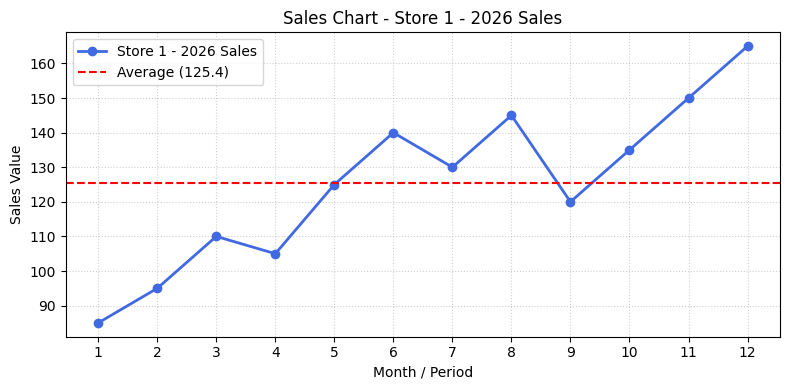

array([ 85,  95, 110, 105, 125, 140, 130, 145, 120, 135, 150, 165])

In [7]:
# Insert 12 months of sales data (e.g. for Store 1)
store_1 = [85, 95, 110, 105, 125, 140, 130, 145, 120, 135, 150, 165]

insert_and_plot(store_1, label="Store 1 - 2026 Sales")

✅ Data stored! Total records saved: 2


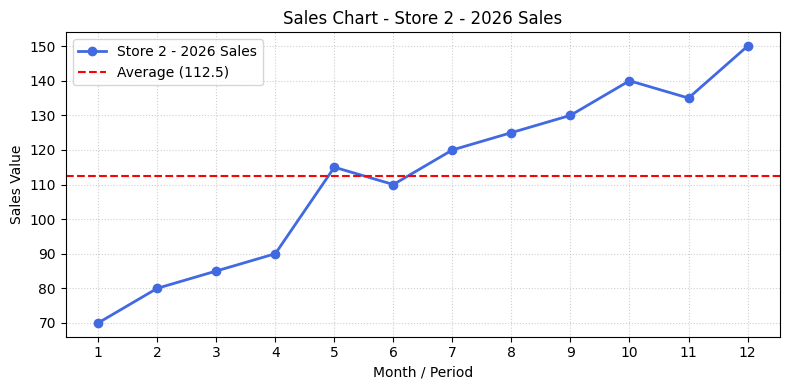

array([ 70,  80,  85,  90, 115, 110, 120, 125, 130, 140, 135, 150])

In [8]:
# Insert data for Store 2
store_2 = [70, 80, 85, 90, 115, 110, 120, 125, 130, 140, 135, 150]

insert_and_plot(store_2, label="Store 2 - 2026 Sales")

In [9]:
stored_sales_records = []

# Store the sales dataset
stored_sales_records.append(sales)

# Check how many datasets have been saved
print("Total records stored:", len(stored_sales_records))

# Access the first stored dataset
print("First record:", stored_sales_records[0])

Total records stored: 1
First record: [[101 142  64 121 110  70 132 136 124 124 137 149]
 [ 73  52  71 102  51 137  79  87  51 113 109  70]
 [ 82 125 107  71 138  98 140 108  91 141 109 129]
 [ 64 111 111  96 111 100 104 113  52 100  56  70]
 [122  88  67  53 138 109  63  58 139 102  51 133]
 [141 109 120  93  57  96  84 127 130  85  99  53]
 [ 51  55 103  53 103 142 112  67 139  93  83 123]
 [111 149  63 144  97  64 121 127 136 111  89 134]
 [129 131 102  73  75 138 109  90  78  64  94 114]
 [138 120  58 137  50  57 137 112  60 130  57  84]]
